# Phase 1: Spatial Topology, Dasymetric Downscaling & Panel Construction
**Objective:** Join the infrastructure layer (Notebook 01) and the demand data (Notebook 02) into one **sub-county × quarter panel**. The 17 CA national data volumes are distributed across sub-counties with a time-varying, mass-preserving dasymetric weight, and the two forecasting targets of the study are defined: **capacity stress** (binary) and the **traffic-load gap** (downscaled GB above the stress threshold).

| | |
|---|---|
| **Pipeline** | 01 Spatial canvas → 02 Temporal extraction → **03 Spatial downscale** → 04 MTL engine → 05 Explainability & NDS |
| **Answers** | Research Questions 1–2 and Specific Objective 1 (a mass-preserving sub-county-quarter dataset, checked against Ookla speeds) |
| **Inputs** | `sites_all_technologies.csv` (01), `ookla_kenya_clean.parquet` and `ca_quarterly_telemetry_imputed.csv` (02), all in `Data/processed/` |
| **Outputs** | `Data/processed/subcounty_panel.parquet` (+ `.csv`), `Data/processed/site_catchment_demand.parquet`; Tables 4.5–4.8; Figure 4.5 |

**What this notebook does, in plain words.** The Communications Authority of Kenya (CA) publishes only one national figure per quarter for the mobile data consumed in the whole country. The study needs to know *where* that traffic is, so this notebook shares the national total out among the 294 sub-counties in the cell registry, using Ookla speed-test activity as a guide to where people use mobile data. It then compares each sub-county's share of the traffic with the amount of network equipment recorded there, and labels the sub-counties where traffic is highest relative to equipment as "stressed". These labels, and the amount of traffic above the stress threshold, are what the models in Notebook 04 learn to forecast.

**Key terms used in this notebook**
- **Downscaling:** turning a total for a large area (here, all of Kenya) into estimates for smaller areas (here, sub-counties). **Dasymetric** downscaling does this with a helper variable that shows where the quantity is concentrated (here, Ookla devices), instead of spreading it evenly by land area or population.
- **Mass-preserving:** the sub-county pieces add back up exactly to the national total in every quarter, so no traffic is created or lost by the allocation.
- **Panel data:** the same units observed repeatedly over time. Here each row is one sub-county in one quarter, so 294 sub-counties × 17 quarters gives 4,998 rows.
- **Proxy:** a measurable stand-in for something that cannot be observed directly. Ookla device counts are a proxy for where demand is, and weighted cell counts are a proxy for network capacity.
- **Target:** the variable a model is trained to predict. This notebook creates two of them: the binary stress label and the load gap in GB.

**Why the design is time-varying.** A first version of this phase used Voronoi catchment **areas** and cell counts as fixed weights. Every location then followed the national series exactly, so a location that was stressed once stayed stressed forever, and a naive "same as last quarter" forecast predicted stress perfectly (ROC-AUC = 1.0). There was nothing left to learn. The weight below changes with **local** demand (Ookla devices), so locations move into and out of stress and the forecasting problem in Notebook 04 is genuine.

**Road map of the steps**
1. Load the outputs of Notebooks 01 and 02.
2. Link every Ookla tile to its nearest cell site, and so to a sub-county.
3. Choose the unit of analysis (site or sub-county) by comparing Ookla coverage (Table 4.5).
4. Build the sub-county × quarter panel with demand, speeds, infrastructure and national figures.
5. Downscale the national volume and define the two targets (stress label and load gap).
6. Check that sub-counties move into and out of stress (Table 4.6).
7. Check the stress ratio against observed download speeds (Table 4.7, Figure 4.5).
8. Test how sensitive the labels are to the modelling choices (Table 4.8).
9. Save the panel for Notebook 04.

In [1]:
# Shared settings and helpers for all five notebooks: pandas (pd), numpy (np), matplotlib
# (plt), folder paths such as PROCESSED, constants such as TECH_W and STRESS_QUANTILE, and
# the save_table / save_figure functions. 'import *' brings all of them into this notebook.
from project_config import *
# BallTree: a fast nearest-neighbour search structure (finds each tile's closest site, Step 2)
from sklearn.neighbors import BallTree
# Cohen's kappa: agreement between two sets of labels, corrected for chance (Step 8)
from sklearn.metrics import cohen_kappa_score
# Spearman rank correlation, returned together with its p-value (Steps 7 and 8)
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')   # hide library warnings so the output stays readable

## Step 1: Load the Hand-Offs from Notebooks 01 and 02
This step reads the three files saved by the earlier notebooks. Each one gives a different piece of the picture:
- `sites` (from Notebook 01): one row per approximate cell site, with its position (`lat`, `lon`), its county and sub-county, and how many GSM (2G), UMTS (3G) and LTE (4G) cells it has (`n_GSM`, `n_UMTS`, `n_LTE`). This is the **supply side**: where the network equipment is.
- `ookla` (from Notebook 02): one row per Ookla tile per quarter (a "tile-quarter"), with the number of speed tests, the number of devices that ran them, and the average download speed, upload speed and latency. This is the **local demand signal**.
- `ca` (from Notebook 02): one row per quarter with the CA national totals, including `Total_Data_Consumed_GB` (the national data volume, written $Y_t$ below), `Total_Smartphones` and the `imputed_quarter` flag.

`index_col='site_id'` makes the site identifier the row label (the **index**) of `sites`, so a site can be looked up directly by its ID in Step 2.

In [2]:
# Read the three hand-off files. PROCESSED is the folder 'Data/processed/' (project_config).
# index_col='site_id' makes the site ID the row label, so sites can be looked up by ID later.
sites = pd.read_csv(PROCESSED + 'sites_all_technologies.csv', index_col='site_id')
# Parquet is a compact binary table format that loads quickly and keeps the column types
ookla = pd.read_parquet(PROCESSED + 'ookla_kenya_clean.parquet')
# The quarter-on-quarter growth column is not needed here, so it is dropped on loading
ca = pd.read_csv(PROCESSED + 'ca_quarterly_telemetry_imputed.csv').drop(columns='qoq_growth_%')
# f-string: the values inside {} are filled in; ':,' adds thousands separators (e.g. 12,345)
print(f"Sites: {len(sites):,} | Ookla tile-quarters (inside Kenya): {len(ookla):,} | CA quarters: {len(ca)}")

Sites: 40,724 | Ookla tile-quarters (inside Kenya): 70,378 | CA quarters: 17


**How to read this output:** the line reports the size of each input: the number of approximate sites, the number of Ookla tile-quarter rows inside Kenya, and the number of CA quarters, which should be 17. If any of these is zero or much smaller than in Notebooks 01 and 02, one of the earlier notebooks has not been run (or not run to the end).

## Step 2: Ookla Tiles → Nearest Site (Voronoi Assignment)
Each tile is assigned to its **nearest site** (haversine distance). This is exactly a Voronoi allocation, without having to build and clip polygons. Tiles more than 10 km from any recorded site are dropped, because their nearest site is unlikely to serve them.

**Why this is needed.** Ookla tiles and cell sites are two separate sets of points on the map. To say how much demand falls on which part of the network, every tile has to be linked to the site most likely to serve it. A phone normally connects to a nearby site, so the nearest site is a reasonable approximation.

**Key ideas**
- **Voronoi allocation:** if you draw, around every site, the region of all points that are closer to that site than to any other site, you get a Voronoi diagram, and each region is that site's **catchment**. Giving each tile to its nearest site puts it in exactly the catchment the Voronoi polygon would, so the polygons never have to be drawn.
- **Haversine distance:** the distance between two points measured along the Earth's curved surface (the great-circle distance), computed from their latitudes and longitudes. Treating latitude and longitude as flat x-y coordinates would distort distances.
- **BallTree:** a scikit-learn data structure that organises the site coordinates so that the nearest site to each tile can be found quickly, instead of measuring the distance from every tile to every site.

**How the code does it.** `BallTree(..., metric='haversine')` is built on the site coordinates, converted to radians because the haversine metric requires them. `tree.query(..., k=1)` returns, for every tile, the distance to the single nearest site (`k=1`) and that site's row position. The distance comes back in radians (as if the Earth had radius 1), so it is multiplied by the Earth's radius (`EARTH_R`, in metres) and divided by 1,000 to give kilometres. The boolean mask `kept` then drops tiles further than `MAX_TILE_DIST_KM` = 10 km. Each kept tile takes the **sub-county of its nearest site**, which is how tiles are placed in sub-counties.

The step also saves `site_catchment_demand.parquet`: the total tests and devices in each site's catchment in each quarter. It is not used for the targets, but Notebook 05 uses it to list candidate sites inside the priority sub-counties.

In [3]:
# Build the search tree on the site positions. The haversine metric expects [latitude,
# longitude] in radians, so np.radians converts the degrees first; .values turns the two
# columns into a plain numpy array.
tree = BallTree(np.radians(sites[['lat', 'lon']].values), metric='haversine')
# For every tile, find the k=1 nearest site. 'dist' holds the distance (in radians, i.e. on a
# sphere of radius 1) and 'idx' the row position of that site in 'sites'. Both are 2-D arrays
# with a single column because k=1.
dist, idx = tree.query(np.radians(ookla[['lat', 'lon']].values), k=1)
# [:, 0] takes the first (only) column. Radians x Earth radius (m) = metres; / 1000 = km.
ookla['dist_km'] = dist[:, 0] * EARTH_R / 1000
# Turn the row position into the actual site ID by reading the index of 'sites'
ookla['site_id'] = sites.index.values[idx[:, 0]]

# Boolean mask: one True/False value per row, True where the tile is within 10 km of a site
kept = ookla['dist_km'] <= MAX_TILE_DIST_KM
# The mean of a True/False column is the share of True values (True counts as 1), here the
# share of tile-quarter rows kept. .loc[kept, 'tests'] selects the 'tests' column for the
# kept rows only, so the second figure is the share of all speed tests that is kept.
print(f"Tiles kept within {MAX_TILE_DIST_KM} km of a site: {kept.mean():.1%} (tests kept: {ookla.loc[kept, 'tests'].sum() / ookla['tests'].sum():.1%})")
ookla = ookla[kept].copy()   # keep only the True rows; .copy() makes an independent table
# .map() looks up each site_id in the 'subcounty' column of 'sites' (matched on its index),
# so each tile inherits the sub-county of its nearest site
ookla['subcounty'] = ookla['site_id'].map(sites['subcounty'])

# Demand observed in each site's catchment (used for the candidate-site lists in Notebook 05)
# groupby + agg gives one output row per (site, quarter). tests=('tests', 'sum') means "new
# column 'tests' = sum of the 'tests' column within the group". reset_index() turns the two
# group keys back into ordinary columns.
site_demand = ookla.groupby(['site_id', 'q_idx']).agg(tests=('tests', 'sum'), devices=('devices', 'sum')).reset_index()
# index=False: the row numbers are not written to the file
site_demand.to_parquet(PROCESSED + 'site_catchment_demand.parquet', index=False)
print(f"[saved] {PROCESSED}site_catchment_demand.parquet ({len(site_demand):,} site-quarters with Ookla data)")

Tiles kept within 10 km of a site: 98.7% (tests kept: 99.3%)
[saved] Data/processed/site_catchment_demand.parquet (62,627 site-quarters with Ookla data)


**How to read this output:** the first line gives the share of Ookla tile-quarter rows that lie within 10 km of a recorded site, and in brackets the share of all speed tests those rows contain. Comparing the two shows how much demand information the 10 km rule throws away: if the share of tests kept is at least as high as the share of tiles kept, the dropped (remote) tiles carry relatively few tests. The second line is the number of site-quarters that received at least one Ookla tile, which is the number of rows in the saved file.

## Step 3: Choosing the Unit of Analysis: Sites or Sub-Counties?
The proposal planned the **site-quarter** as the unit of analysis. That needs a local demand signal for each site in each quarter, and the only one available is Ookla. Table 4.5 compares how much Ookla information each candidate unit receives.

The **unit of analysis** is the "thing" that each row of the dataset describes. A smaller unit gives more geographic detail, but each unit then receives fewer speed tests, and a demand share built from one or two tests is mostly noise. Table 4.5 therefore measures, for each candidate unit, how often a unit-quarter has any Ookla data at all, and how often it has enough data to be trusted.

**How the code does it.** `coverage()` is a small function (defined with `def`) that is run twice: once with `site_id` and once with `subcounty` as the unit. It sums the tests in each unit-quarter and returns one row of Table 4.5 as a Python dictionary:
- **Units** and **Unit-quarters:** the number of units, and units × 17 quarters (every possible row).
- **With any Ookla test (%):** the share of unit-quarters that received at least one Ookla tile.
- **With ≥ 20 tests (%):** the share with at least `LOW_TESTS` = 20 tests, the level this study treats as a reasonably reliable quarter.
- **Median tests (tested unit-quarters):** the typical number of tests among the unit-quarters that have any.
- **Never tested in 17 quarters (%):** the share of units that did not receive a single Ookla tile in any quarter.

In [4]:
Q = ca['q_idx'].nunique()   # number of quarters (nunique = number of distinct values)
# Summarise Ookla coverage for one candidate unit. unit_col is the column that names the unit,
# n_units the number of such units, and label the name shown in the table.
def coverage(unit_col, n_units, label):
    # Total tests per (unit, quarter). Only unit-quarters with at least one tile appear in t,
    # so len(t) is the number of unit-quarters that have any Ookla data.
    t = ookla.groupby([unit_col, 'q_idx'])['tests'].sum()
    # Return one table row as a dictionary {column name: value}. (t >= LOW_TESTS) is True/False
    # per unit-quarter and .sum() counts the True values. The last entry is the share of units
    # that never appear in the Ookla data at all.
    return {'Unit': label, 'Units': n_units, 'Unit-quarters': n_units * Q,
            'With any Ookla test (%)': 100 * len(t) / (n_units * Q),
            f'With ≥ {LOW_TESTS} tests (%)': 100 * (t >= LOW_TESTS).sum() / (n_units * Q),
            'Median tests (tested unit-quarters)': t.median(),
            'Never tested in 17 quarters (%)': 100 * (1 - ookla[unit_col].nunique() / n_units)}
# A list of dictionaries becomes a DataFrame with one row per dictionary; .round(1) = 1 decimal
t45 = pd.DataFrame([coverage('site_id', len(sites), 'Approximate site'),
                    coverage('subcounty', sites['subcounty'].nunique(), 'Sub-county')]).round(1)
print("Table 4.5: Ookla coverage by candidate unit of analysis")
# save_table writes Outputs/tables/T4.05_unit_of_analysis_coverage.csv and returns the table;
# display() (provided by Jupyter) then shows it as a formatted table
display(save_table(t45, '4.05', 'unit_of_analysis_coverage'))

Table 4.5: Ookla coverage by candidate unit of analysis
[saved] Outputs/tables/T4.05_unit_of_analysis_coverage.csv


,Unit,Units,Unit-quarters,With any Ookla test (%),With ≥ 20 tests (%),Median tests (tested unit-quarters),Never tested in 17 quarters (%)
0,Approximate site,40724,692308,9.0,0.3,2.0,69.4
1,Sub-county,294,4998,88.9,42.8,18.0,0.3


**How to read Table 4.5:** compare the two rows column by column. "With any Ookla test (%)" shows how often a unit-quarter has any demand signal, "With ≥ 20 tests (%)" how often it has enough tests to be trusted, and "Never tested in 17 quarters (%)" how many units would have no demand information in any quarter at all.

**Decision:** at site level most site-quarters have no Ookla test at all, so a site's demand weight would be mostly zeros and noise. The unit of analysis is therefore the **sub-county-quarter**. Sites remain the building blocks: they define the catchments and the capacity, and they are used again in Notebook 05 to list candidate sites inside the priority sub-counties. The sub-county is also a reporting level named in the proposal (Sections 1.5, 1.6 and 3.2.1). This is a declared deviation from the proposal.

## Step 4: Sub-County × Quarter Panel
Speeds are averaged weighted by the number of tests. Sub-county-quarters with no tests keep zero counts and missing speeds.

This step builds the **panel**: a table with exactly one row for every sub-county in every quarter. It is put together from three pieces:
1. **Ookla demand and speeds per sub-county-quarter** (`agg`): total tests, total devices, number of tiles, and the test-weighted sums needed for the average speeds.
2. **Fixed infrastructure attributes per sub-county** (`sc`): county, number of sites, numbers of GSM, UMTS and LTE cells, the mean location confidence of the sites (`mean_samples`, from Notebook 01) and the average site position (`lat`, `lon`). These come from the 2019 cell registry, so they do not change over time.
3. **National CA figures per quarter** (`ca`): the national data volume, smartphones and the imputed-quarter flag, copied onto every sub-county in that quarter.

**Test-weighted average speed.** A tile with many tests tells us more about local speed than a tile with one test, so each tile's average speed is multiplied by its number of tests, the products are added up, and the total is divided by the total number of tests. *Illustration (made-up numbers):* tile A has 10 tests at 20 Mbps and tile B has 30 tests at 40 Mbps. The test-weighted average is (10×20 + 30×40) / 40 = 35 Mbps, whereas a simple average of the two tiles would give 30 Mbps. Ookla reports speeds in kbps, so the code divides by 1,000 to get Mbps.

**Filling the gaps.** Some sub-counties have no Ookla tiles in some quarters, so they are missing from `agg`. `reindex` adds those rows back: their counts are set to 0 and their speeds are left missing (`NaN`, "not a number"), because there is nothing to average.

**Two quality flags** are added for the later notebooks. Neither removes any rows.
- `low_confidence = 1` when a sub-county-quarter has fewer than `LOW_TESTS` = 20 Ookla tests, so its demand share rests on very little data.
- `sparse_infrastructure = 1` when a sub-county has fewer than `SPARSE_SITES` = 5 recorded sites. Its capacity proxy is then probably understated: so few recorded sites more likely reflect thin crowdsourced records than an unserved area (see Notebook 01).

In [5]:
# Pre-multiply each tile's average speeds and latency by its number of tests. Adding up these
# products and dividing by the total tests (below) gives a test-weighted average.
for c in ['avg_d_kbps', 'avg_u_kbps', 'avg_lat_ms']:
    ookla['w_' + c] = ookla[c] * ookla['tests']   # e.g. creates the column 'w_avg_d_kbps'
# Ookla totals per (sub-county, quarter). 'size' counts rows, i.e. the number of tile-quarters.
# Devices are added up over tiles, so a phone tested in two tiles is counted twice
# (the device total is therefore an approximate count of devices).
agg = ookla.groupby(['subcounty', 'q_idx']).agg(
    tests=('tests', 'sum'), devices=('devices', 'sum'), tiles=('quadkey', 'size'),
    w_dl=('w_avg_d_kbps', 'sum'), w_ul=('w_avg_u_kbps', 'sum'), w_lat=('w_avg_lat_ms', 'sum'))

# Fixed infrastructure attributes per sub-county, aggregated from its sites.
# lambda x: x.mode()[0] is a small inline function giving the most common county among the
# sub-county's sites (mode() returns the most frequent value(s); [0] takes the first).
# n_sites counts the rows ('size'; any column would do); cell counts are added up; the
# position is the simple average of the site positions.
sc = sites.groupby('subcounty').agg(
    county=('county', lambda x: x.mode()[0]), n_sites=('n_cells', 'size'),
    n_GSM=('n_GSM', 'sum'), n_UMTS=('n_UMTS', 'sum'), n_LTE=('n_LTE', 'sum'),
    mean_samples=('mean_samples', 'mean'), lat=('lat', 'mean'), lon=('lon', 'mean'))

# Every sub-county paired with every quarter (294 x 17 combinations), as a two-level index
full_idx = pd.MultiIndex.from_product([sc.index, ca['q_idx']], names=['subcounty', 'q_idx'])
# reindex puts agg onto that complete list of rows. Combinations missing from agg (no Ookla
# tiles) appear as NaN, and fillna(0) sets their counts to 0. reset_index() turns 'subcounty'
# and 'q_idx' back into ordinary columns.
panel = agg.reindex(full_idx).fillna(0).reset_index()
# np.where(condition, A, B) works row by row: A where the condition is True, otherwise B.
# Weighted average speed = sum(speed x tests) / sum(tests), converted from kbps to Mbps.
# Rows without tests get NaN (missing) instead of a misleading speed of 0. Latency stays
# in milliseconds, so it is not divided by 1000.
panel['dl_mbps'] = np.where(panel.tests > 0, panel.w_dl / panel.tests / 1000, np.nan)
panel['ul_mbps'] = np.where(panel.tests > 0, panel.w_ul / panel.tests / 1000, np.nan)
panel['latency_ms'] = np.where(panel.tests > 0, panel.w_lat / panel.tests, np.nan)
# Drop the helper sums, then attach the sub-county attributes and the national CA figures.
# merge() joins two tables on a shared key: left_on='subcounty' with right_index=True matches
# the panel's 'subcounty' column to the index of sc, and on='q_idx' copies each quarter's
# national values to every sub-county. The rows are then sorted by sub-county and quarter
# (Steps 5 and 6 rely on this order) and renumbered 0, 1, 2, ... by reset_index(drop=True).
panel = (panel.drop(columns=['w_dl', 'w_ul', 'w_lat'])
              .merge(sc, left_on='subcounty', right_index=True)
              .merge(ca, on='q_idx')
              .sort_values(['subcounty', 'q_idx']).reset_index(drop=True))
# Quality flags: each comparison gives True/False, and .astype(int) turns them into 1/0
panel['low_confidence'] = (panel['tests'] < LOW_TESTS).astype(int)
panel['sparse_infrastructure'] = (panel['n_sites'] < SPARSE_SITES).astype(int)   # capacity proxy probably understated
# panel.subcounty is a shortcut for panel['subcounty']; nunique() counts distinct values
print(f"Panel: {len(panel):,} sub-county-quarters ({panel.subcounty.nunique()} sub-counties x {panel.q_idx.nunique()} quarters)")
# The mean of the 0/1 flag is the share of low-confidence rows, so 1 minus it is the share
# of rows with at least 20 tests
print(f"Share with >= {LOW_TESTS} Ookla tests: {1 - panel.low_confidence.mean():.1%}")
# sc[sc.n_sites < SPARSE_SITES] keeps the sparse sub-counties; .shape[0] is their number
print(f"Sub-counties with fewer than {SPARSE_SITES} recorded sites (sparse infrastructure data): {sc[sc.n_sites < SPARSE_SITES].shape[0]}")

Panel: 4,998 sub-county-quarters (294 sub-counties x 17 quarters)
Share with >= 20 Ookla tests: 42.8%
Sub-counties with fewer than 5 recorded sites (sparse infrastructure data): 23


**How to read this output:** the first line confirms the shape of the panel: 294 sub-counties × 17 quarters, one row each. The second line is the share of sub-county-quarters with at least 20 Ookla tests, i.e. the rows whose demand share rests on a reasonable amount of data; all other rows carry `low_confidence = 1`. The third line counts the sub-counties flagged as `sparse_infrastructure`. Both flags are kept as information: Notebook 04 uses `low_confidence` as a model input, and Notebook 05 uses both flags to say how much confidence to place in each sub-county's result.

## Step 5: Time-Varying Dasymetric Downscaling and Targets
This is the core step of the notebook. It turns the national data volume into a load estimate for every sub-county-quarter, compares that load with a capacity proxy, and defines the two targets. The formal definitions come first, then the same five parts in words with a small worked illustration.

1. **Demand weight** (no look-ahead): Ookla device share, averaged over a 2-quarter rolling window and an expanding historical mean, so that sparse quarters are smoothed:
$$d_{s,t} = \frac{\text{devices}_{s,t}}{\sum_j \text{devices}_{j,t}}, \quad \tilde w_{s,t} = 0.5\,\overline{d}^{\,(2q)}_{s,t} + 0.5\,\overline{d}^{\,(\le t)}_{s,t}, \quad W_{s,t} = \frac{\tilde w_{s,t}}{\sum_j \tilde w_{j,t}}$$
2. **Downscaled load** (mass-preserving): $\text{load}_{s,t} = Y_t \times W_{s,t}$, so $\sum_s \text{load}_{s,t} = Y_t$ in every quarter, where $Y_t$ is the CA national data volume.
3. **Relative capacity proxy** (supply side only): $C_s = 0.1\,n^{GSM}_s + 1.0\,n^{UMTS}_s + 5.0\,n^{LTE}_s$. The technology weights reflect the order-of-magnitude differences in per-cell throughput and are varied in Step 8.
4. **Relative stress target:** a sub-county is stressed in quarter $t$ when its load-to-capacity ratio $r_{s,t} = \text{load}_{s,t}/C_s$ is in the top 20% of that quarter, $\tau_t = Q_{0.8}(r_{\cdot,t})$. Because $C_s$ is a relative proxy, stress is defined relative to other sub-counties, not against an absolute engineering limit. A fixed training-period threshold is kept as a sensitivity variant.
5. **Load gap:** $\text{gap}_{s,t} = \max(0,\ \text{load}_{s,t} - \tau_t C_s)$ in GB, i.e. the traffic above the stress threshold.

In these formulas $s$ stands for a sub-county, $t$ for a quarter, and $\sum_j$ means "add up over all sub-counties $j$ in that quarter".

### The five parts in words
**Part 1: the demand weight $W_{s,t}$.**
- $d_{s,t}$ is the **demand share**: the sub-county's share of all Ookla devices recorded in Kenya in that quarter. *Illustration (made-up numbers):* if 1,000 devices were recorded nationally in a quarter and 50 of them were in sub-county A, A's demand share is 50 / 1,000 = 0.05.
- A single quarter of Ookla data is noisy, because a few extra testers can swing a small sub-county's share. The share is therefore **smoothed** by blending two averages with weight 0.5 each: $\overline{d}^{\,(2q)}$, the mean of the current and the previous quarter (the **2-quarter rolling window**), and $\overline{d}^{\,(\le t)}$, the mean of all quarters from the first up to and including $t$ (the **expanding historical mean**).
- **No look-ahead** means that the weight for quarter $t$ uses only quarter $t$ and earlier quarters, never later ones, so it contains nothing that would not have been known at the time.
- Finally the blended values are rescaled so that they add up to exactly 1 across all sub-counties in each quarter. This rescaled value is $W_{s,t}$, and the rescaling is what makes the allocation mass-preserving.
- *Illustration:* if A's shares in the first three quarters were 0.04, 0.06 and 0.05, then in the third quarter the rolling mean is (0.06 + 0.05) / 2 = 0.055, the expanding mean is (0.04 + 0.06 + 0.05) / 3 = 0.05, and $\tilde w$ = 0.5 × 0.055 + 0.5 × 0.05 = 0.0525, before rescaling.

**Part 2: the downscaled load.** The national volume $Y_t$ is shared out in proportion to $W_{s,t}$. *Illustration:* with $Y_t$ = 1,000,000 GB and $W_{s,t}$ = 0.04, the sub-county's load is 0.04 × 1,000,000 = 40,000 GB. Because the $W$ values of a quarter add up to 1, the loads of that quarter add back up to $Y_t$.

**Part 3: the capacity proxy $C_s$.** Real capacity cannot be observed, so it is approximated by counting the cells in each sub-county and giving each technology a **capacity weight**: how much traffic one cell of that type is assumed to carry compared with one UMTS (3G) cell. An LTE (4G) cell counts as 5 units, a UMTS cell as 1 and a GSM (2G) cell as 0.1. *Illustration:* a sub-county with 2 LTE cells and 1 GSM cell has C = 2×5 + 1×0.1 = 10.1; one with 6 LTE, 15 UMTS and 50 GSM cells has C = 30 + 15 + 5 = 50. The proxy is **relative**: it ranks sub-counties by their recorded equipment, it is not a capacity measured in GB.

**Part 4: the stress label and the threshold $\tau_t$.** The load-to-capacity ratio $r_{s,t}$ is the load per capacity unit. In each quarter the ratios of all 294 sub-counties are compared, and $\tau_t$ (the Greek letter tau) is their **80th percentile**: the value that 80% of sub-counties are at or below. The sub-counties above $\tau_t$, the **top 20%**, get stress label 1 and all others get 0. *Illustration:* the sub-county from Part 2 with load 40,000 GB and C = 50 has r = 40,000 / 50 = 800 GB per capacity unit. If that quarter's $\tau_t$ is 600, it is stressed (800 > 600); a sub-county with r = 500 is not.

**Part 5: the load gap.** $\tau_t C_s$ is the load the sub-county could carry while sitting exactly at the stress threshold. The **gap** is the part of its load above that level, and 0 when the load is below it. *Illustration:* continuing the example, $\tau_t C_s$ = 600 × 50 = 30,000 GB, so the gap is 40,000 − 30,000 = 10,000 GB. For the sub-county with r = 500 the difference is negative, so its gap is max(0, negative number) = 0. The gap is therefore positive exactly in the stressed sub-county-quarters and zero in all the others.

### What the national figure affects
**What the CA series does and does not affect.** $Y_t$ multiplies every sub-county's ratio in quarter $t$ by the same factor, so it cancels in $r_{s,t}/\tau_t$. The stress label and the relative ratio therefore depend only on the Ookla device weights and the capacity proxy. The CA series, including its three imputed quarters, affects only the **size** of the load and the gap in GB. *Illustration:* if $Y_t$ were doubled, every load and every ratio would double, $\tau_t$ would double too, and exactly the same sub-counties would be in the top 20%; only the gaps in GB would double.

**Units.** `load_GB` and the gap are **downscaled estimates**: shares of the national volume allocated by the demand weight, not measured traffic. The threshold $\tau_t C_s$ converts a relative capacity proxy into GB, so the gap is "allocated traffic above the quarter's top-20% threshold", not an engineering shortfall. Later tables label it as an estimate.

### How the code does it
| In the formulas | In the code | Meaning |
|---|---|---|
| $d_{s,t}$ | `dev_share` | sub-county's share of the quarter's Ookla devices |
| $\overline{d}^{\,(2q)}_{s,t}$ | `roll2` | 2-quarter rolling mean of the share |
| $\overline{d}^{\,(\le t)}_{s,t}$ | `prior` | expanding mean of the share up to quarter $t$ |
| $\tilde w_{s,t}$ | `w_raw` | 0.5 × `roll2` + 0.5 × `prior` |
| $W_{s,t}$ | `W_st` | `w_raw` rescaled to add up to 1 in each quarter |
| $Y_t$ | `Total_Data_Consumed_GB` | CA national data volume |
| $\text{load}_{s,t}$ | `load_GB` | downscaled load (GB, an estimate) |
| $C_s$ | `capacity_units` | relative capacity proxy, built from `TECH_W` |
| $r_{s,t}$ | `load_capacity_ratio` | load per capacity unit |
| $\tau_t$ | `tau_t` | 80th percentile (`STRESS_QUANTILE` = 0.80) of the ratio in quarter $t$ |
| stress label | `capacity_breach_target` | 1 if $r_{s,t} > \tau_t$, otherwise 0 |
| load gap | `traffic_deficit_GB` | $\max(0,\ \text{load}_{s,t} - \tau_t C_s)$ |

Two further columns are created. `local_smartphones` applies the same weight $W_{s,t}$ to the national smartphone count, giving a downscaled smartphone estimate. `breach_fixed_threshold` is the sensitivity variant mentioned in Part 4: it uses one fixed threshold for all quarters, the 80th percentile of all ratios from the development period (quarters up to `TRAIN_MAX_Q` = 12, pooled together). The last lines of the cell check mass preservation and print the stress rates.

A pandas idea used several times here is **`groupby(...).transform(...)`**: it computes something within each group (for example the total devices of a quarter) and writes the result back onto every row of that group, so the result has the same length as the panel and can be used directly in row-by-row arithmetic.

In [6]:
# g groups the panel rows by sub-county. It keeps a reference to 'panel', so it can also reach
# the 'dev_share' column created on the next line.
g = panel.groupby('subcounty')
# Demand share d_st = devices / total devices in that quarter. transform('sum') puts the
# quarter total on every row of that quarter (same length as the panel), unlike a plain
# groupby sum, which would return one row per quarter.
panel['dev_share'] = panel['devices'] / panel.groupby('q_idx')['devices'].transform('sum')
# Within each sub-county (rows are in quarter order), the 2-quarter rolling mean: the average
# of this quarter and the previous one. min_periods=1 lets the first quarter use itself alone.
roll2 = g['dev_share'].transform(lambda s: s.rolling(2, min_periods=1).mean())
# Expanding mean: the average of all quarters so far, from the first up to the current one
prior = g['dev_share'].transform(lambda s: s.expanding().mean())
w_raw = 0.5 * roll2 + 0.5 * prior   # equal-weight blend of the two smoothed shares
# Rescale so that the weights add up to exactly 1 within each quarter (this is W_st)
panel['W_st'] = w_raw / w_raw.groupby(panel['q_idx']).transform('sum')
# Downscaled load: national GB x the sub-county's weight (mass-preserving by construction)
panel['load_GB'] = panel['Total_Data_Consumed_GB'] * panel['W_st']
# The same weight applied to the national smartphone count: a local smartphone estimate
panel['local_smartphones'] = panel['Total_Smartphones'] * panel['W_st']

# Capacity proxy C_s = 0.1 x GSM + 1 x UMTS + 5 x LTE cells. TECH_W.items() gives the pairs
# ('GSM', 0.1), ('UMTS', 1.0), ('LTE', 5.0); sum() adds the three weighted cell-count columns.
panel['capacity_units'] = sum(w * panel['n_' + r] for r, w in TECH_W.items())
panel['load_capacity_ratio'] = panel['load_GB'] / panel['capacity_units']   # r_st

# Main target: relative stress (top 20% of the quarter)
# tau_t = the 80th percentile (STRESS_QUANTILE = 0.80) of the ratio within each quarter,
# written onto every row of that quarter by transform
panel['tau_t'] = panel.groupby('q_idx')['load_capacity_ratio'].transform(lambda s: s.quantile(STRESS_QUANTILE))
# Stress label: 1 if the ratio is above that quarter's threshold, otherwise 0
panel['capacity_breach_target'] = (panel['load_capacity_ratio'] > panel['tau_t']).astype(int)
# Load gap = max(0, load - tau_t x C): .clip(lower=0) replaces every negative value with 0
panel['traffic_deficit_GB'] = (panel['load_GB'] - panel['tau_t'] * panel['capacity_units']).clip(lower=0)

# Sensitivity target: fixed threshold from the development period only
# .loc[rows, column] selects the ratios of quarters 0 to TRAIN_MAX_Q (= 12), pooled; their 80th
# percentile is one single number, used as the threshold in every quarter
tau_fixed = panel.loc[panel.q_idx <= TRAIN_MAX_Q, 'load_capacity_ratio'].quantile(STRESS_QUANTILE)
panel['breach_fixed_threshold'] = (panel['load_capacity_ratio'] > tau_fixed).astype(int)

# Mass-preservation check
# Sum of the sub-county loads per quarter divided by the CA national total of that quarter.
# Both are indexed by q_idx, so pandas divides quarter by quarter; every value should be 1.
chk = panel.groupby('q_idx')['load_GB'].sum() / ca.set_index('q_idx')['Total_Data_Consumed_GB']
# ':.6f' prints 6 decimals; ':.1%' prints a share as a percentage with 1 decimal
print(f"Mass preservation (sum of load / national total): min {chk.min():.6f}, max {chk.max():.6f}")
print(f"Stress rate (relative): {panel.capacity_breach_target.mean():.1%} | zero-gap share: {(panel.traffic_deficit_GB == 0).mean():.1%}")
# Share of stressed sub-counties in each quarter under the fixed threshold, as a plain list
print("Fixed-threshold stress rate by quarter:", panel.groupby('q_idx').breach_fixed_threshold.mean().round(2).tolist())

Mass preservation (sum of load / national total): min 1.000000, max 1.000000
Stress rate (relative): 20.1% | zero-gap share: 79.9%
Fixed-threshold stress rate by quarter: [0.1, 0.11, 0.12, 0.12, 0.13, 0.14, 0.14, 0.18, 0.18, 0.2, 0.3, 0.41, 0.47, 0.52, 0.6, 0.7, 0.74]


**How to read this output**
- **Mass preservation:** in every quarter, the sum of the sub-county loads divided by the CA national total. The minimum and maximum over the 17 quarters should both be 1.000000, which means the allocation neither creates nor loses traffic.
- **Stress rate (relative):** the share of all sub-county-quarters with stress label 1. It is close to 20% by construction, because the label marks the top 20% of each quarter. **Zero-gap share:** the share with a gap of exactly 0. Since the gap is positive exactly when the label is 1, the two numbers add up to about 100%.
- **Fixed-threshold stress rate by quarter:** the share of sub-counties that would be stressed in each quarter (from the first to the last) if one fixed threshold from the development period were used. National traffic grows over time, so more and more sub-counties exceed a fixed threshold and the list rises. Step 8 comes back to this when explaining why the relative threshold is used.

## Step 6: Stress Is Not Fixed by Construction
Sub-counties move **into and out of** stress from one quarter to the next. This is the variation that the models in Notebook 04 have to learn.

**Why this check matters.** If the same sub-counties were stressed in every quarter, a model could simply copy last quarter's label and be right every time, so forecasting would be trivial. That is what happened with the first, fixed-weight design described at the top of this notebook. Table 4.6 counts how often the label of the same sub-county changes between consecutive quarters.

**How the code does it.** `shift()` within each sub-county moves the labels down by one row, so each row sees the label of the **previous quarter** (`prev`) next to the label of the current quarter (`cur`). The four combinations are counted with **boolean masks**: `(prev == 0) & (cur == 1)` is True only for rows that were unstressed in the previous quarter and are stressed now. The first quarter of each sub-county has no previous quarter (`prev` is missing), so it is not counted, and the four rows of the table add up to 294 × 16 quarter-to-quarter transitions.

**How to read Table 4.6:** the two "stay" rows show persistence, and the "enter" and "leave" rows show the changes that a forecasting model has to anticipate. Because the stress share is about 20% in every quarter, each sub-county that enters stress roughly has to be balanced by another that leaves it, so the "enter" and "leave" counts are similar.

In [7]:
# Previous quarter's label for the same sub-county: shift() moves the values down one row
# within each group, and the first quarter gets NaN (missing) because nothing comes before it
prev = panel.groupby('subcounty')['capacity_breach_target'].shift()
cur = panel['capacity_breach_target']
# Count the four transitions. & means "and" for True/False columns (each comparison needs its
# own brackets) and .sum() counts the True values. NaN == 0 is False, so the first quarter of
# every sub-county is left out of all four counts.
t46 = pd.DataFrame({'Transition': ['stay unstressed (0→0)', 'enter stress (0→1)', 'leave stress (1→0)', 'stay stressed (1→1)'],
                    'Sub-county-quarters': [((prev == 0) & (cur == 0)).sum(), ((prev == 0) & (cur == 1)).sum(),
                                            ((prev == 1) & (cur == 0)).sum(), ((prev == 1) & (cur == 1)).sum()]})
print("Table 4.6: Quarter-to-quarter stress transitions")
display(save_table(t46, '4.06', 'stress_transitions'))

Table 4.6: Quarter-to-quarter stress transitions
[saved] Outputs/tables/T4.06_stress_transitions.csv


,Transition,Sub-county-quarters
0,stay unstressed (0→0),3609
1,enter stress (0→1),151
2,leave stress (1→0),151
3,stay stressed (1→1),793


## Step 7: Consistency Check Against Observed Speeds
If the stress ratio is meaningful, sub-counties with a higher load-to-capacity ratio should show **slower observed download speeds**. Spearman correlations are computed within each quarter, using only sub-county-quarters with at least 20 Ookla tests.

Two limits apply. The test is within-quarter and rank-based, so it checks the device-share/capacity **ranking**, not the CA totals. The speeds come from the same Ookla tiles as the demand weights, so this is a **consistency check** rather than fully external validation. To see which part of the ratio drives the result, the same correlation is also computed for its two parts separately: the downscaled load alone, and 1/capacity alone.

**Spearman correlation (ρ, "rho").** It measures whether two variables move together in rank order: ρ close to −1 means that the higher one is, the lower the other tends to be; ρ close to +1 means they rise together; ρ close to 0 means no consistent ordering. Because it uses ranks rather than raw values, a few extreme sub-counties cannot dominate it. The **p-value** tests whether ρ differs from zero, and p < 0.05 is treated as significant.

**Expected signs.** More load per unit of capacity should mean slower speeds, so the ratio should be **negatively** correlated with download speed, and so should 1/capacity (less equipment, slower speeds). If the load alone captured congestion, it would be negatively correlated as well.

**How the code does it.** `validate()` loops over the quarters (`for q, dq in ...groupby('q_idx')` gives each quarter's number `q` and its rows `dq`), keeps only rows with `low_confidence == 0` (at least 20 tests) and computes Spearman's ρ between the chosen column and `dl_mbps`. It returns one row per quarter. It is run three times, on the ratio, on `load_GB` alone and on `inv_capacity` = 1/capacity alone, and the three sets of results are placed side by side in Table 4.7. The small helper `sig` counts the quarters in which ρ has the expected sign and p < 0.05. Figure 4.5 plots the ratio's ρ for each quarter, with dark bars for the significant quarters.

Table 4.7: Within-quarter Spearman correlation with observed download speed: load/capacity ratio and its two parts
[saved] Outputs/tables/T4.07_speed_consistency_check.csv


,q_idx,Quarter,n,spearman_rho,p_value,rho_load_only,p_load_only,rho_inv_capacity_only,p_inv_capacity_only
0,0,Q3_21_22,103,0.109,0.2721,0.286,0.0034,-0.189,0.0565
1,1,Q4_21_22,96,-0.170,0.0979,0.227,0.0261,-0.215,0.0353
2,2,Q1_22_23,84,-0.042,0.7049,0.146,0.1861,-0.147,0.1809
3,3,Q2_22_23,92,-0.173,0.0988,0.363,0.0004,-0.372,0.0003
4,4,Q3_22_23,92,-0.079,0.4515,0.486,0.0000,-0.436,0.0000
5,5,Q4_22_23,88,0.006,0.9543,0.362,0.0005,-0.317,0.0026
6,6,Q1_23_24,101,-0.250,0.0116,0.388,0.0001,-0.424,0.0000
7,7,Q2_23_24,106,-0.100,0.3054,0.518,0.0000,-0.454,0.0000
8,8,Q3_23_24,103,-0.213,0.0308,0.370,0.0001,-0.390,0.0000
9,9,Q4_23_24,115,-0.403,0.0000,0.572,0.0000,-0.614,0.0000


Load/capacity ratio: median rho -0.173, negative and significant in 8 of 17 quarters
Downscaled load only: median rho +0.443, positive and significant in 16 of 17
1/capacity only: median rho -0.430, negative and significant in 15 of 17


[saved] Outputs/figures/F4.05_speed_consistency_check.png


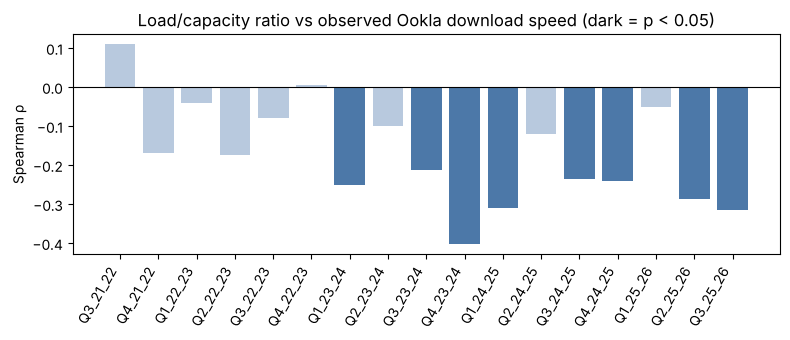

In [8]:
# Spearman correlation between a chosen column and the observed download speed, per quarter.
# d is a panel-like table; ratio_col is the column to test (default: the load/capacity ratio).
def validate(d, ratio_col='load_capacity_ratio'):
    rows = []   # collects one dictionary per quarter
    # Keep the rows with at least 20 tests, then loop over the quarters: groupby yields pairs
    # of (quarter number q, sub-table dq holding that quarter's rows)
    for q, dq in d[d.low_confidence == 0].groupby('q_idx'):
        rho, p = spearmanr(dq[ratio_col], dq['dl_mbps'])   # correlation and its p-value
        # .iloc[0] is the first row by position, used to read the quarter's name
        rows.append({'q_idx': q, 'Quarter': dq['Quarter'].iloc[0], 'n': len(dq), 'spearman_rho': round(rho, 3), 'p_value': round(p, 4)})
    return pd.DataFrame(rows)   # one row per quarter

# 1/capacity: larger where there is less recorded equipment
panel['inv_capacity'] = 1 / panel['capacity_units']
validation = validate(panel)   # the full load/capacity ratio
# The two parts of the ratio tested separately (two calls, unpacked into two names on one line)
v_load, v_cap = validate(panel, 'load_GB'), validate(panel, 'inv_capacity')
# Add the parts' rho and p-value as extra columns (the rows match quarter by quarter)
validation['rho_load_only'], validation['p_load_only'] = v_load['spearman_rho'], v_load['p_value']
validation['rho_inv_capacity_only'], validation['p_inv_capacity_only'] = v_cap['spearman_rho'], v_cap['p_value']
print("Table 4.7: Within-quarter Spearman correlation with observed download speed: load/capacity ratio and its two parts")
display(save_table(validation, '4.07', 'speed_consistency_check'))
# sig: a small inline function (lambda) counting the quarters where rho has the expected sign
# (np.sign gives -1, 0 or +1) and the p-value is below 0.05
sig = lambda r, p, sign: int(((np.sign(r) == sign) & (p < 0.05)).sum())
# ':+.3f' prints the number with its sign (+ or -) and 3 decimals
print(f"Load/capacity ratio: median rho {validation.spearman_rho.median():+.3f}, "
      f"negative and significant in {sig(validation.spearman_rho, validation.p_value, -1)} of {len(validation)} quarters")
print(f"Downscaled load only: median rho {validation.rho_load_only.median():+.3f}, "
      f"positive and significant in {sig(validation.rho_load_only, validation.p_load_only, 1)} of {len(validation)}")
print(f"1/capacity only: median rho {validation.rho_inv_capacity_only.median():+.3f}, "
      f"negative and significant in {sig(validation.rho_inv_capacity_only, validation.p_inv_capacity_only, -1)} of {len(validation)}")

# Figure 4.5: one bar per quarter showing the ratio's rho; dark blue if p < 0.05, else pale.
# np.where picks the colour of each bar from its p-value.
fig, ax = plt.subplots(figsize=(8, 3.5))   # figure size in inches (width, height)
ax.bar(validation['Quarter'], validation['spearman_rho'],
       color=np.where(validation['p_value'] < 0.05, '#4c78a8', '#b8c9de'))
ax.axhline(0, color='black', lw=0.8)   # reference line at rho = 0
ax.set_ylabel('Spearman ρ'); ax.set_title('Load/capacity ratio vs observed Ookla download speed (dark = p < 0.05)')
plt.xticks(rotation=60, ha='right'); plt.tight_layout()   # tilt quarter labels; fit layout
save_figure('4.05', 'speed_consistency_check'); plt.show()   # save F4.05_...png, then show

**Reading the check:** the load/capacity ratio is weakly and mostly negatively correlated with observed speed (median ρ = −0.17, negative and significant in 8 of 17 quarters). Splitting the ratio shows that the sign comes from the **capacity proxy**: 1/capacity alone gives a stronger negative correlation (median ρ = −0.43, 15 of 17), while the downscaled load alone is **positively** related to speed (median ρ = +0.44, 16 of 17), because high-demand sub-counties are also the better-served urban ones. The check therefore supports the ordering of the capacity proxy, but it does **not** independently validate the demand allocation; it mainly reflects the urban-rural gradient in recorded infrastructure. This is reported as a limitation, and Table 4.8 includes a uniform-load variant that drops the demand information entirely.

In plain words: sub-counties with little recorded equipment tend to have slower speeds, and that is what gives the ratio its negative correlation. Sub-counties with high Ookla demand are mostly urban and tend to be faster, so demand on its own does not look like congestion in this check. In Table 4.7, compare the `spearman_rho` column with `rho_load_only` and `rho_inv_capacity_only` quarter by quarter; in Figure 4.5, dark bars below zero are the quarters where the ratio passes the check.

## Step 8: Sensitivity of the Targets to the Allocation Choices
The technology weights and the smoothing of the demand weight are modelling choices. Each variant below rebuilds the stress label with one choice changed and compares it with the main specification.
- **Agreement** and **Cohen's κ**: how many sub-county-quarters keep the same stress label.
- **Ratio ρ**: mean within-quarter Spearman correlation of the load/capacity ratio with the main version.
- **Speed check**: the consistency check of Step 7 repeated for the variant.
- The **uniform-load** variant gives every sub-county the same load, so its ratio is just 1/capacity. Comparing it with the main specification shows what the Ookla demand weights add to the label.

**Sensitivity analysis** asks: "if a different but still reasonable choice had been made, would the answer change?" If the stress labels hardly change, the results do not hinge on arbitrary choices; if they change a lot, that choice matters and has to be justified.

**The variants in words**
- **Technology weights 0.2 / 1 / 3 (flatter)** and **0.05 / 1 / 10 (steeper):** LTE cells count for less or for more compared with older cells.
- **Equal weight per cell (1 / 1 / 1):** every cell counts the same, whatever its technology.
- **Demand weight from tests instead of devices:** the demand share is built from the number of speed tests.
- **Current quarter only (no smoothing)** and **expanding mean only:** the demand weight uses only $d_{s,t}$, or only the expanding mean, instead of the 0.5 / 0.5 blend.
- **Fixed threshold from development period:** one threshold for all quarters (the `breach_fixed_threshold` column from Step 5).
- **Uniform load:** every sub-county gets the same share of the national volume, so the Ookla data play no part.

**Cohen's κ (kappa).** Raw label agreement flatters the comparison. With 20% of rows stressed in both versions, two completely unrelated labellings would still agree on about 0.8 × 0.8 + 0.2 × 0.2 = 0.68, i.e. 68% of rows, mostly by both saying "not stressed". κ removes this chance agreement: κ = (observed agreement − chance agreement) / (1 − chance agreement), so κ = 1 is perfect agreement and κ = 0 is no better than chance. *Illustration (made-up numbers):* 92% observed agreement gives κ = (0.92 − 0.68) / (1 − 0.68) = 0.75.

**How the code does it.** `variant()` repeats the calculations of Step 5 on a copy of the panel, with the choices passed as arguments; its default values reproduce the main specification. `VARIANTS` is a dictionary from each variant's name to the arguments that differ from the defaults, and `variant(**kw)` unpacks that dictionary into keyword arguments, so `{'smoothing': 'uniform'}` becomes `variant(smoothing='uniform')`. The first row, "Main specification (check)", changes nothing and should reproduce the main labels exactly (agreement 100%, κ = 1), which confirms that `variant()` rebuilds Step 5 correctly. For every variant the loop records the stress rate, the agreement and κ with the main label, the mean within-quarter ρ between the two ratios, and the Step 7 speed check.

In [9]:
# Rebuild the stress label with one allocation choice changed. The defaults reproduce the
# main specification: tech_w = capacity weights per technology, share_col = column used for
# the demand share, smoothing = how the share is smoothed, fixed_tau = True for one threshold
# in all quarters.
def variant(tech_w=TECH_W, share_col='devices', smoothing='main', fixed_tau=False):
    # Work on a copy of only the columns needed, so the main panel is never changed
    d = panel[['subcounty', 'q_idx', 'Quarter', 'Total_Data_Consumed_GB', 'n_GSM', 'n_UMTS', 'n_LTE',
               'tests', 'devices', 'dl_mbps', 'low_confidence']].copy()
    # Demand share within each quarter (from devices, or from tests in one variant)
    share = d[share_col] / d.groupby('q_idx')[share_col].transform('sum')
    # The same two smoothed versions as in Step 5, computed within each sub-county
    roll = share.groupby(d['subcounty']).transform(lambda s: s.rolling(2, min_periods=1).mean())
    expd = share.groupby(d['subcounty']).transform(lambda s: s.expanding().mean())
    # A dictionary holding the four weighting options; [smoothing] picks the one requested.
    # 'uniform' gives every sub-county the same weight (1.0), i.e. no demand information.
    w = {'main': 0.5 * roll + 0.5 * expd, 'current quarter only': share, 'expanding mean only': expd,
         'uniform': pd.Series(1.0, index=d.index)}[smoothing]
    # Rescale the weight within each quarter and share out the national volume (as in Step 5)
    d['load_GB'] = d['Total_Data_Consumed_GB'] * w / w.groupby(d['q_idx']).transform('sum')
    # Ratio with this variant's technology weights (same weighted sum as in Step 5)
    d['load_capacity_ratio'] = d['load_GB'] / sum(v * d['n_' + r] for r, v in tech_w.items())
    if fixed_tau:
        # One threshold: the 80th percentile of all development-period ratios (quarters 0-12)
        tau = d.loc[d.q_idx <= TRAIN_MAX_Q, 'load_capacity_ratio'].quantile(STRESS_QUANTILE)
    else:
        # Main rule: a separate 80th percentile in every quarter
        tau = d.groupby('q_idx')['load_capacity_ratio'].transform(lambda s: s.quantile(STRESS_QUANTILE))
    d['stress'] = (d['load_capacity_ratio'] > tau).astype(int)   # 1 = stressed (variant)
    return d

# Name of each variant -> the arguments that differ from the defaults ({} = nothing changed)
VARIANTS = {
    'Main specification (check)': {},
    'Technology weights 0.2 / 1 / 3 (flatter)': {'tech_w': {'GSM': 0.2, 'UMTS': 1.0, 'LTE': 3.0}},
    'Technology weights 0.05 / 1 / 10 (steeper)': {'tech_w': {'GSM': 0.05, 'UMTS': 1.0, 'LTE': 10.0}},
    'Equal weight per cell (1 / 1 / 1)': {'tech_w': {'GSM': 1.0, 'UMTS': 1.0, 'LTE': 1.0}},
    'Demand weight from tests instead of devices': {'share_col': 'tests'},
    'Demand weight: current quarter only (no smoothing)': {'smoothing': 'current quarter only'},
    'Demand weight: expanding mean only': {'smoothing': 'expanding mean only'},
    'Fixed threshold from development period': {'fixed_tau': True},
    'Uniform load (no demand information)': {'smoothing': 'uniform'},
}
rows = []
for name, kw in VARIANTS.items():
    d = variant(**kw)   # ** unpacks the dictionary into keyword arguments
    v = validate(d)     # the Step 7 speed check, repeated for this variant
    # Mean within-quarter Spearman rho between the main ratio and the variant's ratio. The list
    # comprehension [... for ...] builds one rho per quarter: zip pairs the two per-quarter
    # groupings, each item is (quarter, values), '_' ignores the quarter, and [0] keeps rho.
    rho_ratio = np.mean([spearmanr(a, b)[0] for (_, a), (_, b) in
                         zip(panel.groupby('q_idx')['load_capacity_ratio'], d.groupby('q_idx')['load_capacity_ratio'])])
    # One table row: stress rate, share of labels equal to the main label, Cohen's kappa,
    # the ratio correlation, and the speed check (median rho; quarters with rho < 0 and
    # p < 0.05)
    rows.append({'Variant': name, 'Stress rate (%)': 100 * d['stress'].mean(),
                 'Label agreement (%)': 100 * (d['stress'] == panel['capacity_breach_target']).mean(),
                 "Cohen's κ": cohen_kappa_score(panel['capacity_breach_target'], d['stress']),
                 'Ratio ρ with main': rho_ratio,
                 'Speed check median ρ': v['spearman_rho'].median(),
                 'Quarters ρ<0, p<0.05': int(((v.spearman_rho < 0) & (v.p_value < 0.05)).sum())})
t48 = pd.DataFrame(rows).round(3)   # one row per variant, rounded to 3 decimals
print("Table 4.8: Sensitivity of the stress target to allocation choices")
display(save_table(t48, '4.08', 'allocation_sensitivity'))

Table 4.8: Sensitivity of the stress target to allocation choices
[saved] Outputs/tables/T4.08_allocation_sensitivity.csv


,Variant,Stress rate (%),Label agreement (%),Cohen's κ,Ratio ρ with main,Speed check median ρ,"Quarters ρ<0, p<0.05"
0,Main specification (check),20.068,100.000,1.000,1.000,-0.173,8
1,Technology weights 0.2 / 1 / 3 (flatter),20.068,96.198,0.882,0.979,-0.167,7
2,Technology weights 0.05 / 1 / 10 (steeper),20.068,96.799,0.900,0.980,-0.196,9
3,Equal weight per cell (1 / 1 / 1),20.068,85.674,0.553,0.782,-0.005,0
4,Demand weight from tests instead of devices,20.068,93.437,0.795,0.930,-0.160,7
5,Demand weight: current quarter only (no smooth...,20.048,89.496,0.672,0.756,-0.199,9
6,Demand weight: expanding mean only,20.068,95.078,0.847,0.948,-0.146,6
7,Fixed threshold from development period,30.372,82.813,0.551,1.000,-0.173,8
8,Uniform load (no demand information),20.068,80.952,0.406,0.318,-0.430,15


**Reading Table 4.8:** other technology weights, a test-based demand weight and an expanding-mean weight keep 93–97% of the stress labels (κ 0.80–0.90), so the label is not fragile to those choices; dropping the smoothing keeps 89% (κ 0.67). Equal weight per cell keeps only 86% (κ 0.55) and its speed check collapses to ρ ≈ 0, which supports weighting cells by technology. The **uniform-load** variant keeps 81% of labels (κ 0.41): the Ookla demand weights change about one label in five, so they shape the target even though the speed check cannot validate them. A fixed development-period threshold drives the stress rate up to 74% by the last quarter (national growth), which is why the relative threshold is used.

Two reading tips. First, look at κ rather than agreement alone: because about 68% agreement is expected by chance (see Step 8), 81% agreement corresponds to a much more modest κ. Second, the "Stress rate (%)" column stays at about 20% for every variant that uses the relative threshold, because that rule always picks the top 20% of each quarter; only the fixed-threshold variant can move away from it.

## Step 9: Export and Hand-Off to Notebook 04
The panel keeps the original target column names (`capacity_breach_target` = stress label, `traffic_deficit_GB` = load gap, a downscaled estimate). The unit identifier is `subcounty`.

The panel is saved twice: as **Parquet** (compact, keeps the data types, and is the file Notebook 04 reads) and as **CSV** (easy to open in Excel). Helper columns such as `inv_capacity` are not exported. The exported columns, in groups:
- **Identifiers and time:** `subcounty`, `county`, `q_idx` (quarter number, 0 to 16), `Quarter`, `imputed_quarter`, `lat`, `lon`.
- **Supply side (fixed over time):** `n_sites`, `n_GSM`, `n_UMTS`, `n_LTE`, `mean_samples`, `capacity_units`.
- **Ookla observations and quality flags:** `tests`, `devices`, `tiles`, `dl_mbps`, `ul_mbps`, `latency_ms`, `low_confidence`, `sparse_infrastructure`.
- **Downscaling:** `dev_share`, `W_st`, `load_GB`, `local_smartphones`, `load_capacity_ratio`, `tau_t`.
- **Targets:** `capacity_breach_target` (stress label), `traffic_deficit_GB` (load gap) and `breach_fixed_threshold` (fixed-threshold sensitivity label).

In [10]:
# The columns handed to Notebook 04, in this order
export_cols = ['subcounty', 'county', 'q_idx', 'Quarter', 'imputed_quarter', 'lat', 'lon',
               'n_sites', 'n_GSM', 'n_UMTS', 'n_LTE', 'mean_samples', 'capacity_units',
               'tests', 'devices', 'tiles', 'dl_mbps', 'ul_mbps', 'latency_ms', 'low_confidence', 'sparse_infrastructure',
               'dev_share', 'W_st', 'load_GB', 'local_smartphones', 'load_capacity_ratio', 'tau_t',
               'capacity_breach_target', 'traffic_deficit_GB', 'breach_fixed_threshold']
# Save the same table twice: Parquet (read by Notebook 04) and CSV (for Excel or inspection)
panel[export_cols].to_parquet(PROCESSED + 'subcounty_panel.parquet', index=False)
panel[export_cols].to_csv(PROCESSED + 'subcounty_panel.csv', index=False)
print(f"[saved] {PROCESSED}subcounty_panel.parquet (+ .csv): {len(panel):,} rows x {len(export_cols)} columns")

[saved] Data/processed/subcounty_panel.parquet (+ .csv): 4,998 rows x 30 columns


**How to read this output:** the line confirms where the panel was saved and its size: one row per sub-county-quarter (294 × 17) and one column per entry of `export_cols`.

### Summary of Notebook 03
- **Unit of analysis:** sub-county-quarter, because Ookla is far too sparse per site (Table 4.5).
- **Panel:** 294 sub-counties × 17 quarters. The downscaled loads add up exactly to the CA national total in every quarter (mass preservation).
- **Targets:** relative capacity stress (top 20% of load/capacity each quarter) and the downscaled load gap above the threshold. The stress label does not depend on the CA totals (they cancel), only on the Ookla device weights and the capacity proxy. Sub-counties enter and leave stress (Table 4.6), so the target is not fixed by construction.
- **Speed check:** the weak negative correlation with observed speeds comes from the capacity proxy; the demand allocation itself is not independently validated (Table 4.7). **Sensitivity:** Table 4.8 shows how much the labels depend on the allocation choices, including a uniform-load variant.
- **Files produced:** `subcounty_panel.parquet` (+ `.csv`) for Notebook 04, and `site_catchment_demand.parquet` for the candidate-site lists in Notebook 05.
- **Next:** Notebook 04 builds the forecasting models on this panel.